<a href="https://colab.research.google.com/github/JaquelinedeJesus/Simulaci-n-2/blob/main/Caminata%20aleatoria%20sobre%20un%20grafo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Caminata aleatoria sobre un grafo**

**Alumna:** Jaqueline de Jesús Espinoza Cano

## **Objetivo:**

Estimar mediante una caminata aleatoria sobre el grafo de buenas cadenas y el método de Monte Carlo, el valor esperado del número de 1's ($μ$) en una cadena binaria de longitud $m=100$ que no contiene 1's adyacentes.
De igual manera, determinar el número total de buenas cadenas de longitud $m=100$.

## **Método**




1.   Para diseñar este algoritmo, partimos de una cadena binaria (compuesta por $0's$  y $1's$) de longitud $m$. Diremos que una cadena es buena cuando no presenta dos $1's$ consecutivos (es decir, no contiene $1's$ adyacentes).
2.   Valor esperado de $1's$: Para una cadena de longitud $m$, el número esperado de $1's$ se define como

$\mu = \sum_{k} k\,\pi_k$

donde $\pi_k$ representa la probabilidad de que una cadena buena contenga exactamente $k$ unos.

3. Función de conteo: Dada una secuencia $x$ formada por $0's$ y $1's$ de longitud $m$, denotamos por $r(x)$ al número total de $1's$ presentes en dicha secuencia.
4. Si limitamos la simulación únicamente a cadenas buenas $Y_0$, $Y_1$, $Y_2$,…, entonces podemos aproximar el valor esperado mediante el Método de Monte Carlo:

$\mu = \frac{r(Y_0) + r(Y_1) + \dots + r(Y_n)}{n}$


# **Ejercicio**

Si $m=100$, ¿Cuántas buenas cadenas hay?

# **Solución**

Cuando $m=100$, el espacio de estados alcanza $2^1$$^0$$^0$, lo cual es una cantidad muy grande. Por lo que intentar generar la matriz de transición o crear todas las secuencias a de cada uno de los estados generaria un error al programarlo.

In [3]:
import random
import numpy as np
import matplotlib.pyplot as plt
from itertools import product


# PASO 1: Verificar si una cadena es "buena" (sin 1s adyacentes)

def es_buena(cadena):

    for i in range(len(cadena) - 1):
        if cadena[i] == 1 and cadena[i + 1] == 1:
            return False
    return True


# PASO 2: Un paso de la caminata aleatoria sobre el grafo implícito (esquema de aceptación / rechazo, verificación O(1))

def caminata_aleatoria(cadena):

    m = len(cadena)
    pos = random.randint(0, m - 1)
    nueva = cadena.copy()

    if cadena[pos] == 1:
        nueva[pos] = 0
        return nueva, pos, True

    else:

        izquierda_ok = (pos == 0) or (cadena[pos - 1] == 0)
        derecha_ok   = (pos == m - 1) or (cadena[pos + 1] == 0)

        if izquierda_ok and derecha_ok:
            nueva[pos] = 1
            return nueva, pos, True
        else:
            return cadena, pos, False


# PASO 3: Valor teórico de μ bajo la distribución uniforme sobre las buenas cadenas de longitud m
def mu_teorico(m):
    """
    Bajo la distribución estacionaria uniforme, la densidad
    esperada de 1s es 1/(1+φ), con φ = (1+√5)/2 (número áureo).
    Por lo tanto, μ = m / (1 + φ).
    """
    phi = (1 + np.sqrt(5)) / 2
    return m / (1 + phi)



# PASO 4: Simulación
if __name__ == "__main__":

    m        = 100
    pasos    = 500_000
    burn_in  = 200_000

    cadena = [0] * m

    print("=" * 65)
    print(f"Caminata aleatoria m = {m}")
    print("=" * 65)
    print(f"Estado inicial: {''.join(map(str, cadena))}")
    print(f"Pasos: {pasos:,}")
    print("-" * 65)

    historial_r  = np.empty(pasos - burn_in, dtype=np.int32)
    historial_mu = np.empty(pasos, dtype=np.float64)

    aceptados = 0
    suma      = 0
    k         = 0

    for t in range(pasos):

        # (a) Ejecutar un paso de la cadena de Markov
        cadena, pos, exito = caminata_aleatoria(cadena)

        # (b) Acumular estadísticas
        aceptados += int(exito)
        r = sum(cadena)
        suma += r
        historial_mu[t] = suma / (t + 1)

        # (c) Guardar r(Y_t)
        if t >= burn_in:
            historial_r[k] = r
            k += 1

        # (d) Reporte cada 100 000 pasos
        if (t + 1) % 100_000 == 0:
            print(f"  Paso {t+1:>8,}: r = {r:>3d}, "
                  f"Tasa de aceptación = {aceptados/(t+1):.4f}")

    # PASO 5: Cálculo de los estimadores y métricas finales

    mu_hat = historial_r.mean()
    sigma  = historial_r.std(ddof=1)
    error  = sigma / np.sqrt(len(historial_r))
    mu_t   = mu_teorico(m)
    tasa   = aceptados / pasos
    phi    = (1 + np.sqrt(5)) / 2

    # PASO 6: Muestra de resultados

    print("\n" + "=" * 65)
    print("RESULTADOS")
    print("=" * 65)
    print(f"Tasa de aceptación : {tasa:.4f}")
    print(f"μ estimado (MC)    : {mu_hat:.5f}  ± {error:.5f}")
    print(f"μ teórico          : {mu_t:.5f}")
    print(f"Diferencia         : {abs(mu_hat - mu_t):.5f}")

    # PASO 7: Número total de buenas cadenas (aprox. por Binet)
    print(f"Número de buenas cadenas B({m}) = F({m+2}) ≈ "
          f"{phi**(m+2)/np.sqrt(5):.4e}")

Caminata aleatoria m = 100
Estado inicial: 0000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
Pasos: 500,000
-----------------------------------------------------------------
  Paso  100,000: r =  28, Tasa de aceptación = 0.5568
  Paso  200,000: r =  31, Tasa de aceptación = 0.5568
  Paso  300,000: r =  26, Tasa de aceptación = 0.5555
  Paso  400,000: r =  35, Tasa de aceptación = 0.5554
  Paso  500,000: r =  28, Tasa de aceptación = 0.5550

RESULTADOS
Tasa de aceptación : 0.5550
μ estimado (MC)    : 27.81493  ± 0.00547
μ teórico          : 38.19660
Diferencia         : 10.38167
Número de buenas cadenas B(100) = F(102) ≈ 9.2737e+20


# **Covergencia de $\mu$**

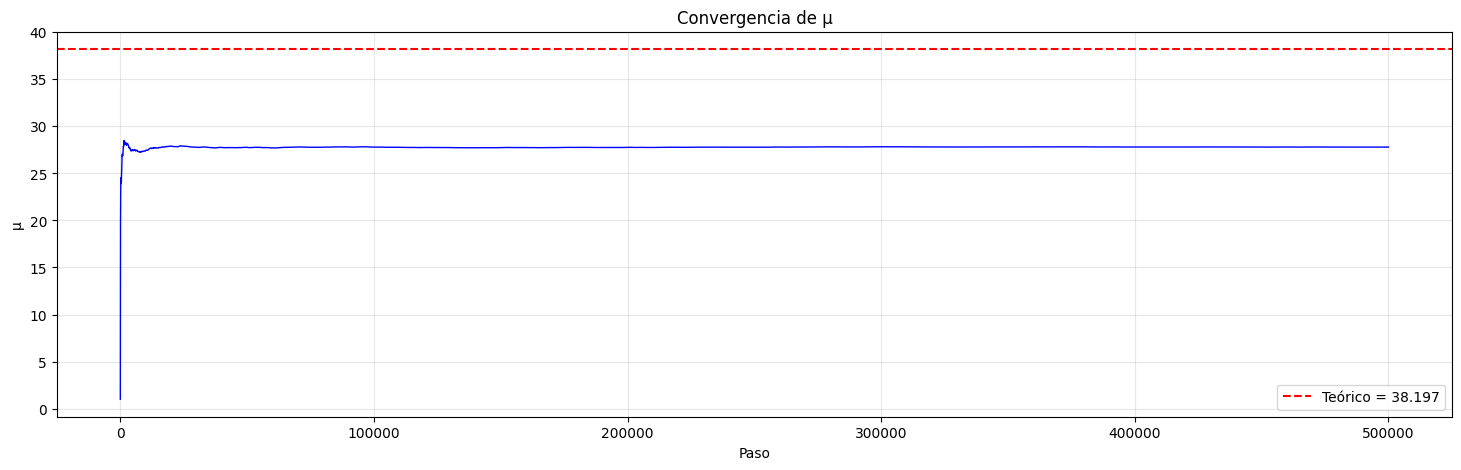

In [5]:
fig, ax = plt.subplots(figsize=(18, 5))

ax.plot(historial_mu, color="blue", lw=1)
ax.axhline(mu_t, color="red", ls="--",
                label=f"Teórico = {mu_t:.3f}")
ax.set_xlabel("Paso")
ax.set_ylabel("μ")
ax.set_title(f"Convergencia de μ")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

# **Serie temporal e histograma de $r(Y)$**

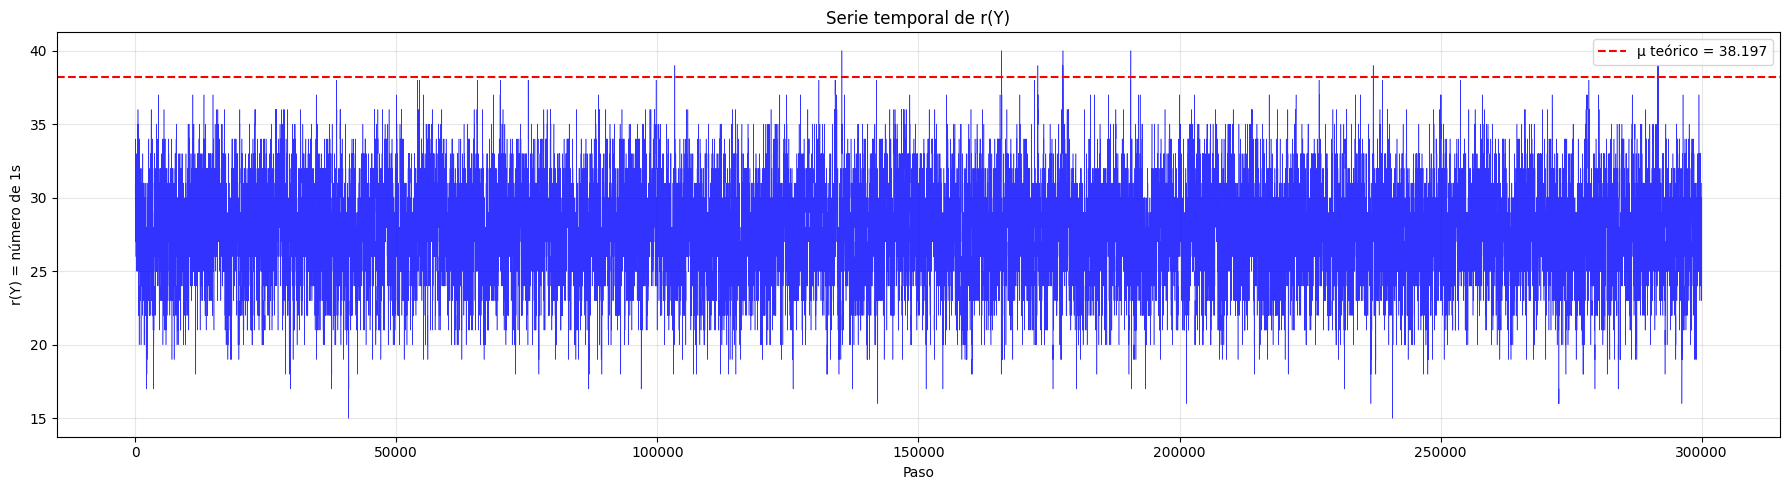

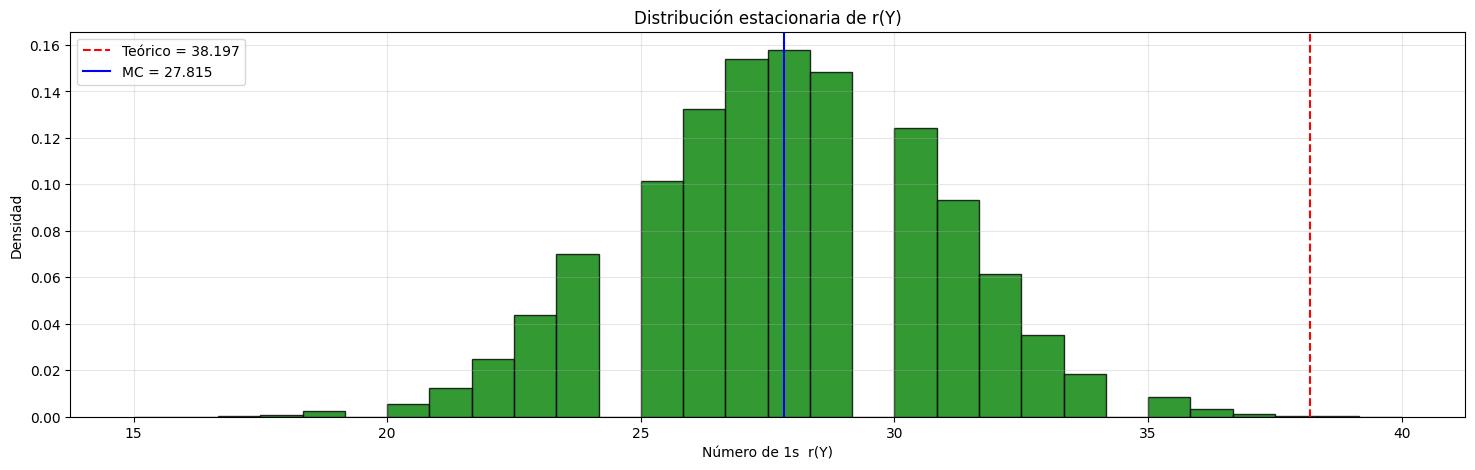

In [7]:
fig, axes = plt.subplots(figsize=(18, 5))

# Serie temporal
axes.plot(historial_r, color="blue", lw=0.4, alpha=0.8)
axes.axhline(mu_t, color="red", ls="--",
                label=f"μ teórico = {mu_t:.3f}")
axes.set_xlabel("Paso")
axes.set_ylabel("r(Y) = número de 1s")
axes.set_title("Serie temporal de r(Y)")
axes.legend()
axes.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Histograma
fig, ax = plt.subplots(figsize=(18, 5))

ax.hist(historial_r, bins=30, density=True,
             color="green", alpha=0.8, edgecolor="black")
ax.axvline(mu_t, color="red", ls="--",
                label=f"Teórico = {mu_t:.3f}")
ax.axvline(mu_hat, color="blue", ls="-",
                label=f"MC = {mu_hat:.3f}")
ax.set_xlabel("Número de 1s  r(Y)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución estacionaria de r(Y)")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

# **Conclusiones**

La simulación con $m=100$ arrojó una tasa de aceptación del $55.56%$,
inferior al valor teórico $(1/\varphi \approx 61.8\%)$, y una estimación
Monte Carlo $(\hat{\mu} = 27.84 \pm 0.005)$, muy alejada del valor teórico
$(\mu = 38.1966)$ (diferencia de 10.35). Por otro lado la gráfica de convergencia muestra que el promedio acumulado se estabiliza en 27.8, por debajo de la línea teórica, mientras que la serie temporal de $r(Y)$ fluctúa entre 15 y 35 unos y el histograma se centra en $\hat{\mu}=27.74$,
desplazado respecto a 38.197. En conjunto, esto indica que la cadena
no alcanzó la distribución estacionaria uniforme sobre las buenas cadenas,
posiblemente por un tiempo de mezcla mayor a los 500,000 pasos
simulados o por falta de reversibilidad en la dinámica de aceptación y
rechazo.